# Returns Abuse and Bad Debt Analysis
Which return behaviors drive refund abuse and bad debt, and which policy changes cut losses without hurting good customers?

The data is synthetic (src/generate_data.py). This notebook reads the SQLite database and query outputs that `src/run_all.py` builds.

In [1]:
import sys, json, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
PROC = ROOT / 'data' / 'processed'
con = sqlite3.connect(ROOT / 'data' / 'returns.db')
pd.set_option('display.width', 160)
m = json.loads((PROC / 'metrics.json').read_text())

## 1. Measure: data quality and program health

In [2]:
pd.read_csv(PROC / '01_data_quality_checks.csv')

,check_name,rows_flagged,handling
0,orders: exact duplicate rows,150,drop duplicates
1,orders: zero or negative item_price,45,exclude order
2,orders: null category,0,exclude order
3,orders: delivered before ordered,0,exclude order
4,returns: exact duplicate rows,60,drop duplicates
5,returns: null reason_code,261,map to unknown
6,returns: order_id not in orders,0,exclude return
7,refunds: exact duplicate rows,40,drop duplicates
8,refunds: return_id not in returns,0,exclude refund
9,refunds: amount above item price,0,review


In [3]:
rr = pd.read_csv(PROC / '03_return_rate_by_category_month.csv')
cat = rr.groupby('category')[['orders','returns','loss_dollars']].sum()
cat['return_rate'] = (cat['returns'] / cat['orders']).round(4)
cat.sort_values('return_rate', ascending=False)

,orders,returns,loss_dollars,return_rate
category,,,,
Apparel,59112,18821,107278.02,0.3184
Shoes,21378,5537,60133.03,0.2590
Electronics,32540,4523,170939.23,0.1390
Sports,28946,2846,16552.02,0.0983
Home & Kitchen,43110,3741,21216.53,0.0868
Toys,19101,1506,6413.70,0.0788
Beauty,23798,1033,3878.86,0.0434
Books,23090,689,2101.01,0.0298


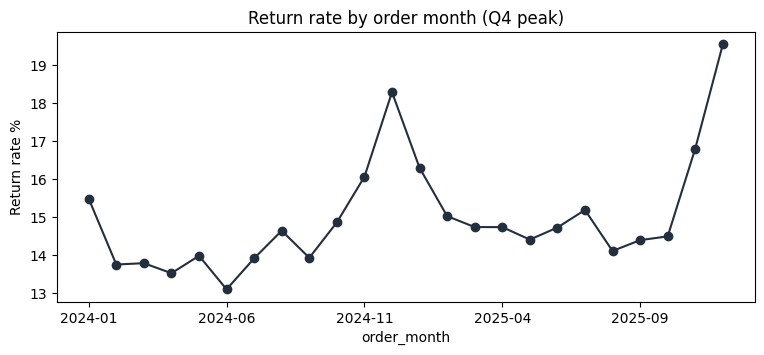

In [4]:
mon = rr.groupby('order_month')[['orders','returns']].sum()
ax = (mon['returns'] / mon['orders'] * 100).plot(figsize=(9,3.5), marker='o', color='#232F3E')
ax.set_ylabel('Return rate %'); ax.set_title('Return rate by order month (Q4 peak)'); plt.show()

In [5]:
pd.read_csv(PROC / '04_return_reason_condition_mix.csv')

,reason_code,returns,pct_of_returns,refund_dollars,pct_received,pct_new,pct_open_box,pct_used,pct_damaged,pct_empty_or_wrong,mismatch_rate_pct,recovery_rate,loss_dollars
0,no_longer_needed,13498,33.95,1069266.33,97.44,53.44,33.74,10.10,2.60,0.12,12.82,0.7282,162382.12
1,size_fit,9650,24.27,531712.76,97.38,53.26,34.62,9.57,2.44,0.12,12.12,0.7430,67095.33
2,defective,6727,16.92,602043.18,96.97,18.78,33.53,9.89,36.32,1.49,1.49,0.4693,28567.80
3,damaged,4570,11.49,349618.16,97.55,18.98,34.52,5.20,39.77,1.53,1.53,0.4727,15746.54
4,wrong_item,3991,10.04,317498.10,96.92,55.79,35.29,5.87,2.43,0.62,8.92,0.7748,29587.55
5,item_not_received,1063,2.67,80162.82,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80162.82
6,unknown,260,0.65,20770.95,95.38,37.90,38.71,10.89,12.10,0.40,23.39,0.6431,4970.24


## 2. Refund cycle time and bad debt

In [6]:
ct = pd.read_csv(PROC / '05_refund_cycle_time.csv')
ct.pivot(index='request_quarter', columns='refund_type', values='avg_days_request_to_refund')

refund_type,instant,standard
request_quarter,,
2024-Q1,0.50,10.63
2024-Q2,0.50,10.11
2024-Q3,0.50,10.14
2024-Q4,0.50,11.66
2025-Q1,0.49,11.07
2025-Q2,0.51,10.10
2025-Q3,0.51,10.22
2025-Q4,0.49,11.69
2026-Q1,0.50,12.19


In [7]:
bd = pd.read_csv(PROC / '06_bad_debt.csv')
bd[bd.refund_month == 'TOTAL']

,refund_month,refund_type,refunds,refund_dollars,bad_debt_refunds,bad_debt_dollars,bad_debt_pct_of_refund_dollars,bad_debt_pct_of_refunds
52,TOTAL,all,38607,2890595.18,971,80031.84,2.769,2.515
53,TOTAL,instant,21522,1623224.91,703,58634.91,3.612,3.266
54,TOTAL,standard,17085,1267370.27,268,21396.93,1.688,1.569


## 3. Analyze: risk features, score and tiers
Features only use activity before 2025-07-01 (the scoring window). The 90-day rolling return rate is a SQL window function with a `RANGE BETWEEN 89 PRECEDING AND CURRENT ROW` frame over order day.

In [8]:
pd.read_csv(PROC / '07_customer_risk_features.csv')

,signal,customers,pct_of_customers
0,customers with scoring-window orders,18953,94.77
1,max 90-day return rate >= 50%,1781,8.90
2,return $ share >= 40%,1900,9.50
3,1+ INR claim,556,2.78
4,1+ condition mismatch,1460,7.30
5,1+ never-received refund,413,2.06
6,address in INR cluster,104,0.52
7,account tenure < 180 days,1622,8.11


In [9]:
pd.read_sql_query('''SELECT risk_tier, risk_score, COUNT(*) AS customers FROM customer_risk
GROUP BY 1, 2 ORDER BY 2 DESC''', con).head(12)

,risk_tier,risk_score,customers
0,High,9,2
1,High,8,13
2,High,7,27
3,High,6,107
4,High,5,137
5,High,4,233
6,Medium,3,332
7,Medium,2,751
8,Low,1,3985
9,Low,0,14413


In [10]:
pd.read_csv(PROC / '09_tier_outcomes_validation.csv')

,risk_tier,customers,active_customers,good_customers,customers_with_loss_event,loss_event_rate_pct,perf_return_rate_pct,loss_dollars,loss_dollars_per_active_customer,pct_of_loss_dollars,pct_of_active_customers
0,High,519,516,211,305,59.11,44.78,48395.83,93.79,31.30,2.70
1,Medium,1083,1060,815,245,23.11,30.91,24287.97,22.91,15.71,5.54
2,Low,18398,17550,16442,1108,6.31,14.12,81938.19,4.67,52.99,91.76


## 4. Statistical validation (held-out Jul-Dec 2025)

In [11]:
import stats_analysis
df = stats_analysis.load()
tests, chi2, p = stats_analysis.tier_tests(df)
tests.round(4)

,test,statistic,dof,p_value,group_a,rate_a,group_b,rate_b
0,Chi-square: tier x loss event,2060.4335,2.0,0.0,All tiers,NaN,,NaN
1,Two-proportion z-test: High vs Low,44.0221,NaN,0.0,High,0.5911,Low,0.0631
2,Two-proportion z-test: Medium vs Low,20.4568,NaN,0.0,Medium,0.2311,Low,0.0631


In [12]:
model, ors = stats_analysis.logit(df)
print(model.summary2().tables[0].to_string(header=False, index=False))
ors.round(3)

             Model:            Logit           Method:         MLE
Dependent Variable:  perf_loss_event Pseudo R-squared:       0.102
              Date: 2026-11-05 14:26              AIC:  10149.0616
  No. Observations:            19126              BIC:  10219.7908
          Df Model:                8   Log-Likelihood:     -5065.5
      Df Residuals:            19117          LL-Null:     -5638.5
         Converged:           1.0000      LLR p-value: 4.5934e-242
    No. Iterations:           7.0000            Scale:      1.0000


,term,description,coef,odds_ratio,or_ci_low,or_ci_high,p_value
0,Intercept,Intercept,-2.976,0.051,0.046,0.056,0.000
1,flag_roll90,90-day return rate >= 50%,1.140,3.128,2.718,3.600,0.000
2,flag_dollar_share,Return $ share >= 50%,0.276,1.318,1.098,1.582,0.003
3,flag_mismatch,1+ condition mismatch,1.272,3.568,3.087,4.126,0.000
4,flag_inr,1+ INR claim,0.615,1.850,1.422,2.406,0.000
5,flag_never_received,1+ never-received refund,1.125,3.080,2.420,3.920,0.000
6,flag_address_cluster,Address in INR cluster,2.417,11.214,7.243,17.363,0.000
7,flag_new_account,Account < 180 days old,0.625,1.867,1.568,2.224,0.000
8,is_member,Member account,0.159,1.172,1.051,1.308,0.004


In [13]:
auc = stats_analysis.auc(df['risk_score'].values, df['perf_loss_event'].values)
print(f'Score AUC on held-out window: {auc:.3f}')
print(f"Loss-event rate High vs Low: {m['high_loss_event_rate']}% vs {m['low_loss_event_rate']}%")

Score AUC on held-out window: 0.675
Loss-event rate High vs Low: 59.11% vs 6.31%


Every rule flag has an odds ratio above 1, and none of the confidence intervals include 1, so each rule earns its points. The address-cluster and condition-mismatch rules carry the most weight. The AUC above says the score ranks risk moderately well. That's fine for a rules-based tier that routes customers to a slower refund flow. It wouldn't be good enough to deny anyone service.

## 5. Improve: abuse patterns and policy simulation

In [14]:
pd.read_csv(PROC / '12_abuse_patterns.csv')

,pattern,events,customers,pct_of_customers,refund_dollars,est_loss_dollars,pct_of_pattern_loss
0,Serial returners (resale value lost),6464,414,2.07,494234.57,182119.03,39.76
1,"Wardrobing (used high-value item, fast return)",569,331,1.66,139975.56,90984.29,19.86
2,"Refund issued, item never received (bad debt)",971,710,3.55,80031.84,80031.84,17.47
3,INR claims at other addresses,754,724,3.62,54565.97,54565.97,11.91
4,INR claims at cluster addresses,235,91,0.46,25596.85,25596.85,5.59
5,Empty-box / wrong-item returned,217,128,0.64,24801.17,24801.17,5.41


In [15]:
pol = pd.read_csv(PROC / '11_policy_simulation.csv')
pol[['scenario','dollars_saved','pct_of_baseline_loss','good_customers_affected','pct_good_customers_affected']]

,scenario,dollars_saved,pct_of_baseline_loss,good_customers_affected,pct_good_customers_affected
0,S0 Baseline: current policy (loss $ in window),0.00,0.00,0,0.00
1,S1 Disable instant refund for High tier,10493.42,6.79,120,0.69
2,"S2 Receipt-before-refund over $X, all customers",16769.53,10.85,267,1.53
3,"S3 Receipt-before-refund over $X, Medium + Hig...",7584.89,4.91,42,0.24
4,S4 Disable instant refund for everyone,37628.73,24.34,4111,23.53
5,"S5 Restocking fee on no-longer-needed, repeat ...",7108.51,4.60,128,0.73
6,S6 Investigate INR claims at cluster addresses,5850.82,3.78,0,0.00
7,S7 Recommended package (S1 + S5 + S6),23452.76,15.17,206,1.18


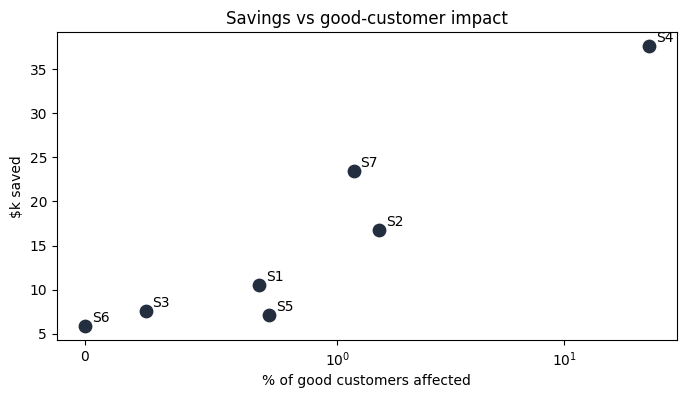

In [16]:
p = pol[pol.scenario_id > 0]
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(p.pct_good_customers_affected, p.dollars_saved/1000, s=80, color='#232F3E')
for _, r in p.iterrows():
    ax.annotate(r.scenario.split(' ')[0], (r.pct_good_customers_affected, r.dollars_saved/1000),
                xytext=(5,3), textcoords='offset points')
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('% of good customers affected')
ax.set_ylabel('$k saved'); ax.set_title('Savings vs good-customer impact'); plt.show()

In [17]:
pd.read_csv(PROC / '10_cohort_view.csv')

,signup_cohort,period,customers,orders,return_rate_pct,loss_dollars_per_1k_orders,pct_high_tier
0,1. before 2022,scoring,9484,88113,14.36,1289.42,2.22
1,1. before 2022,performance,9484,40212,14.82,1390.99,2.22
2,2. 2022,scoring,4201,39089,14.10,1181.81,2.19
3,2. 2022,performance,4201,17761,15.28,1611.97,2.19
4,3. 2023,scoring,2539,23624,15.13,1572.46,2.68
5,3. 2023,performance,2539,10759,16.15,1462.15,2.68
6,4. 2024 H1,scoring,991,8566,20.44,2619.31,6.36
7,4. 2024 H1,performance,991,4459,21.08,3323.27,6.36
8,5. 2024 H2,scoring,1142,5772,20.72,3148.06,4.38
9,5. 2024 H2,performance,1142,4801,21.14,2749.35,4.38


## 6. Recommendation
Go with S7: refund-on-receipt for the High tier, a restocking fee on repeat no-longer-needed returns, and investigation of INR claims at cluster addresses. It saves about 15% of loss dollars and touches roughly 1% of good customers. S4 saves more, but it slows refunds for nearly a quarter of good customers. More detail in docs/Policy_Recommendation_Memo.md.

In [18]:
print(f"S7 saved ${m['s7_saved']:,.0f} ({m['s7_pct_loss']}% of loss), good customers affected {m['s7_pct_good']}%")
print(f"S4 saved ${m['s4_saved']:,.0f} ({m['s4_pct_loss']}% of loss), good customers affected {m['s4_pct_good']}%")
con.close()

S7 saved $23,453 (15.17% of loss), good customers affected 1.18%
S4 saved $37,629 (24.34% of loss), good customers affected 23.53%
